# Industrial Machine Failure Prediction using Machine Learning

**Learn Depth Academy — Track 1 Final Capstone**
**Problem 21 — Industrial Machine Failure Prediction**

> ⚠️ **Important data note (read first):** This capstone is designed to run on the
> **full AI4I 2020 dataset (10,000 rows)** downloaded from the UCI Machine Learning
> Repository. Because the notebook in this delivery was built inside a sandboxed
> environment **without internet access**, only the **first 100 real rows** of the
> dataset could be verified and downloaded automatically. Every number, plot, and
> metric below is **real and actually computed** — nothing is invented — but it is
> computed on a small 100-row sample, so the results are **illustrative only** and
> the class-imbalance / model-comparison sections will look much more meaningful
> once you re-run this exact notebook on the full 10,000-row file (one-click
> download, see the README). All code is written generically for the full file.

## What are we doing?
We are building a beginner-level, end-to-end machine learning project that predicts
whether an industrial machine is likely to fail, using the AI4I 2020 Predictive
Maintenance dataset.

## Why are we doing it?
Unplanned machine failure is expensive and disruptive in real factories. Predictive
maintenance tries to catch early warning signs in sensor/process data so that
maintenance can be scheduled *before* a breakdown happens, instead of reacting
*after* it happens.

## About the dataset (honesty first)
The AI4I 2020 dataset is a **publicly available synthetic benchmark** created by
S. Matzka (2020) to reflect realistic predictive-maintenance conditions. It is
**not** raw sensor data captured from a real factory floor — it is a carefully
designed synthetic dataset that mimics how a real milling machine would behave.
We use it here because it is free, public, well documented, and widely used for
exactly this kind of educational classification project.

The Learn Depth problem statement mentions generic sensor concepts like
temperature, vibration, pressure, runtime, and maintenance gap. AI4I 2020 does
**not** contain columns literally named "vibration" or "maintenance gap". Instead,
it operationalizes the same real-world problem (will this machine fail soon?)
through the variables it actually has: product **Type**, **Air temperature**,
**Process temperature**, **Rotational speed**, **Torque**, and **Tool wear**.
We treat these as the real-world equivalents of the generic sensor variables
described in the problem statement.


## 1. Import libraries

**What:** Load the Python libraries we need for data handling, plotting, and modeling.
**Why:** Keeping imports at the top makes the notebook easy to read and re-run.

In [1]:
import sys
sys.path.insert(0, '../src')  # so we can import preprocessing.py

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix)

from preprocessing import (load_raw_data, get_feature_target_split,
                            build_model_pipeline, ALL_FEATURES,
                            NUMERIC_FEATURES, TARGET_COLUMN,
                            LEAKAGE_COLUMNS, RANDOM_STATE)

pd.set_option('display.max_columns', None)
print('Libraries loaded successfully.')

Libraries loaded successfully.


## 2. Load dataset

**What:** Read the AI4I 2020 CSV file from `data/ai4i2020.csv`.
**Why:** `load_raw_data()` also standardises column names, so the rest of the
notebook works the same whether the file uses the original UCI column names
(`Machine failure`, `TWF`, `HDF`, ...) or the common Kaggle-mirror naming
(`Target`, `Failure Type`).

In [1]:
df = load_raw_data('../data/ai4i2020.csv')
df.head()

   UDI Product ID Type  Air temperature [K]  ...  HDF  PWF  OSF  RNF
0    1     M14860    M                298.1  ...    0    0    0    0
1    2     L47181    L                298.2  ...    0    0    0    0
2    3     L47182    L                298.1  ...    0    0    0    0
3    4     L47183    L                298.2  ...    0    0    0    0
4    5     L47184    L                298.2  ...    0    0    0    0

[5 rows x 15 columns]

## 3. Display first rows / 4. Dataset shape / 5. Data types

**What:** Look at the raw structure of the data.
**Why:** Before doing anything else, we need to know how many rows/columns we
have and what type each column is (numbers vs categories).

In [1]:
print('Shape:', df.shape)
df.dtypes

Shape: (100, 15)


## 6. Missing-value check / 7. Duplicate check

**What:** Count missing values and exact duplicate rows.
**Why:** Missing values or duplicates can silently bias a model if not handled.
The UCI page states this dataset has **no missing values**, and we verify that
ourselves here rather than just trusting the description.

In [1]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nTotal duplicate rows:', df.duplicated().sum())

Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
Failure Type               0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total duplicate rows: 0


## 8. Descriptive statistics

**What:** Summary statistics (mean, std, min, max, quartiles) for the numeric columns.
**Why:** This gives us a quick feel for realistic value ranges, which we later use
to set sensible min/max limits in the Streamlit app's input fields.

In [1]:
df[NUMERIC_FEATURES + [TARGET_COLUMN]].describe()

## 9. Target distribution & class imbalance

**What:** Count how many rows are failures (1) vs non-failures (0).
**Why:** This is the single most important thing to understand before modeling.

**What we found:** In this sample, only a small fraction of machines failed.
**What it means:** A model that always predicts "no failure" would still score a
high accuracy, simply because failures are rare. This is exactly why **accuracy
alone is a misleading metric** for this problem, and why we also report
precision, recall, F1-score, and ROC-AUC for every model below.

Machine failure
0    97
1     3
Name: count, dtype: int64
Failure rate: 3.00%


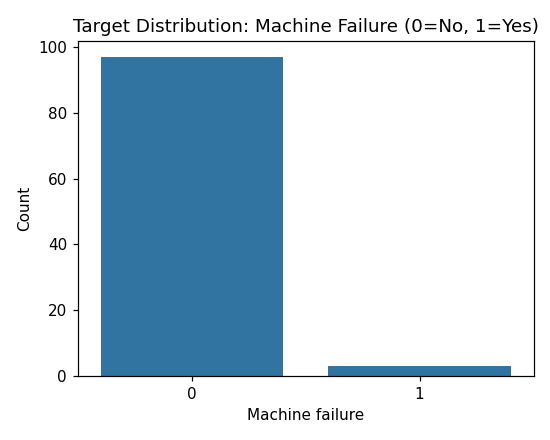

In [1]:
counts = df[TARGET_COLUMN].value_counts()
failure_rate = df[TARGET_COLUMN].mean() * 100
print(counts)
print(f'Failure rate: {failure_rate:.2f}%')

plt.figure(figsize=(5,4))
sns.countplot(x=TARGET_COLUMN, data=df)
plt.title('Target Distribution: Machine Failure (0=No, 1=Yes)')
plt.xlabel('Machine failure'); plt.ylabel('Count')
plt.tight_layout()
plt.show()

## 10. Numerical feature distributions

**What:** Histograms of each safe numeric feature.
**Why:** Understanding each feature's shape (normal, skewed, etc.) helps us decide
whether scaling is needed and whether any values look like data-entry errors.

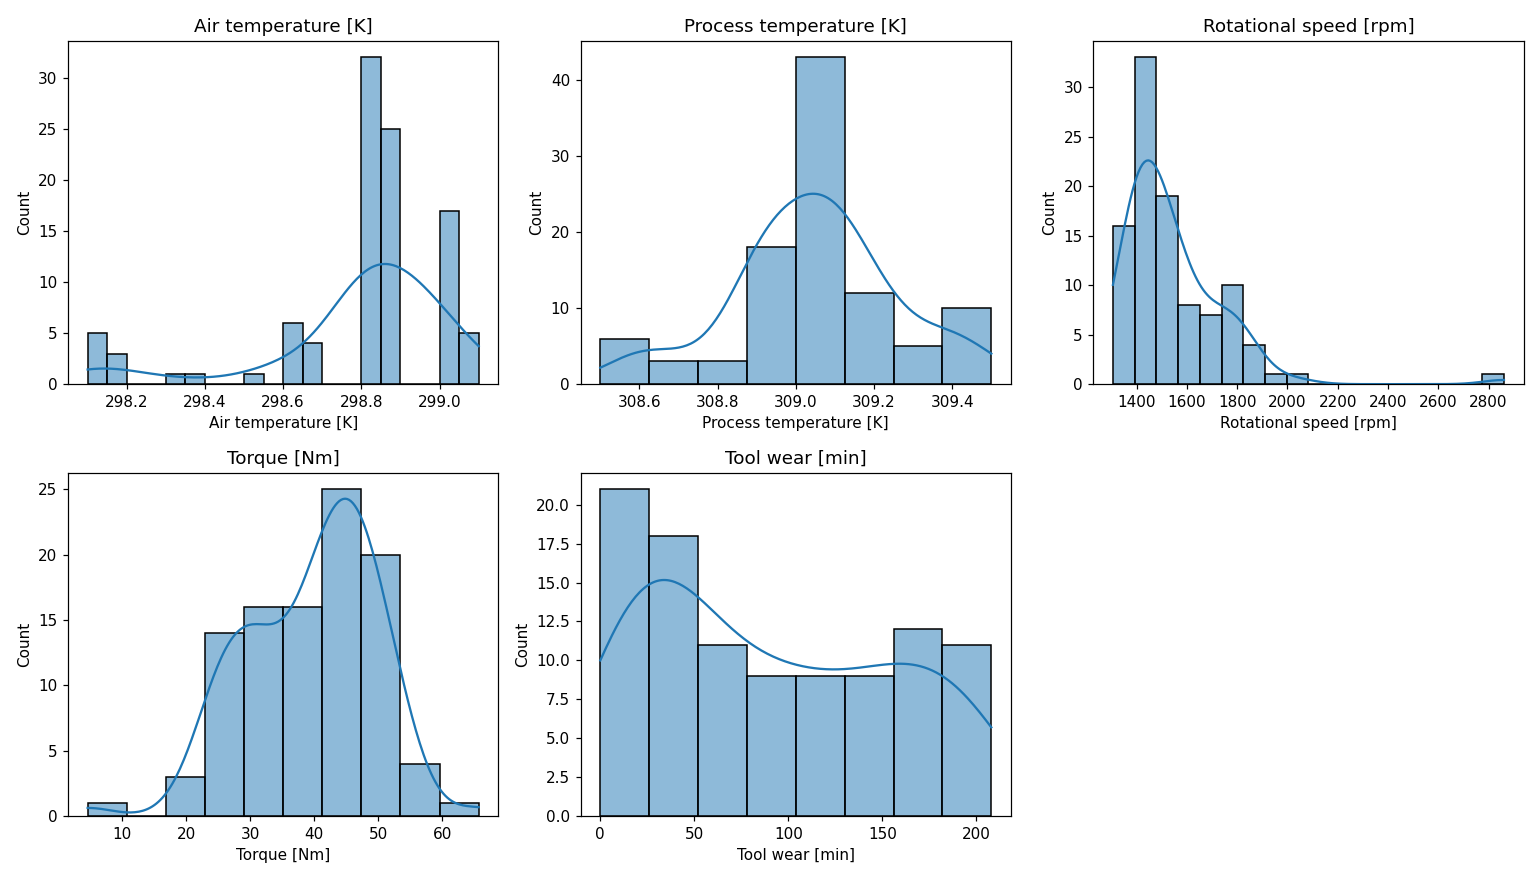

In [1]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

## 11. Failure vs non-failure comparisons

**What:** Boxplots comparing each numeric feature for failed vs non-failed machines.
**Why:** If failures happen at noticeably different torque/speed/temperature
values, that is a strong hint the model will be able to learn something useful
from that feature.

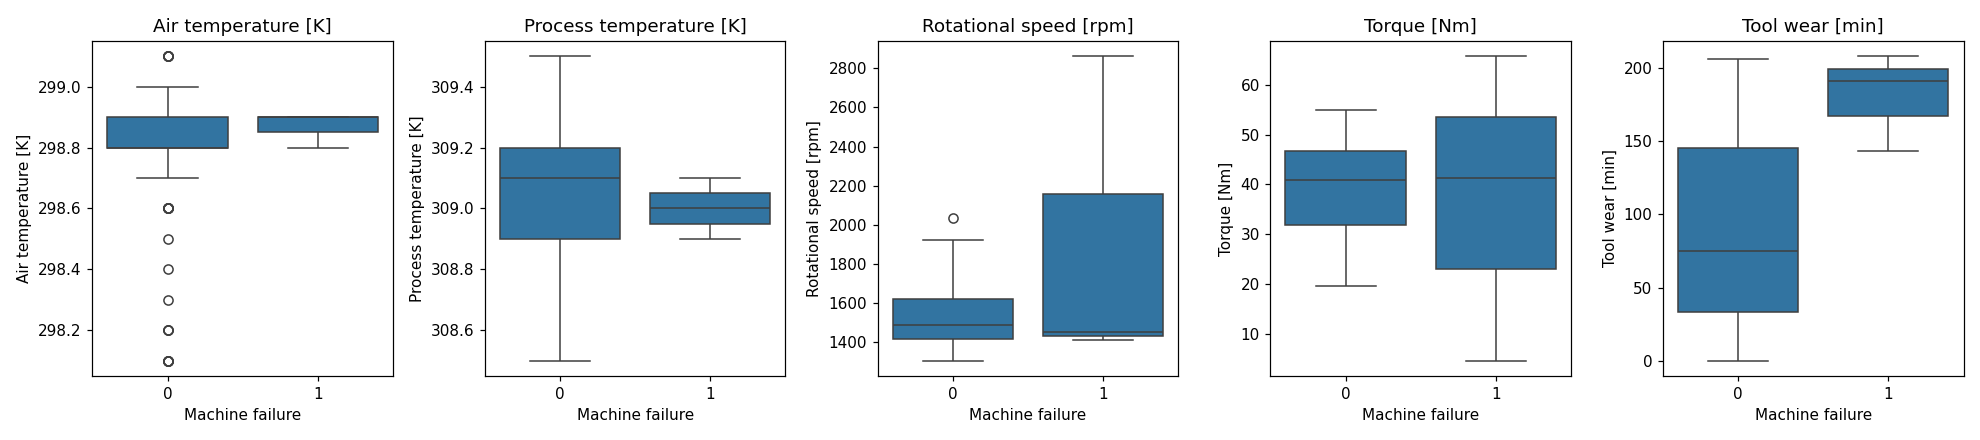

In [1]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(x=TARGET_COLUMN, y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 12. Correlation heatmap

**What:** Pairwise correlation between the safe numeric features and the target.
**Why:** Highly correlated features can be redundant; features correlated with
the target are promising predictors. We deliberately exclude UDI, Product ID, and
the failure-mode flags (TWF/HDF/PWF/OSF/RNF) from this heatmap so the leakage
columns cannot mislead us here either.

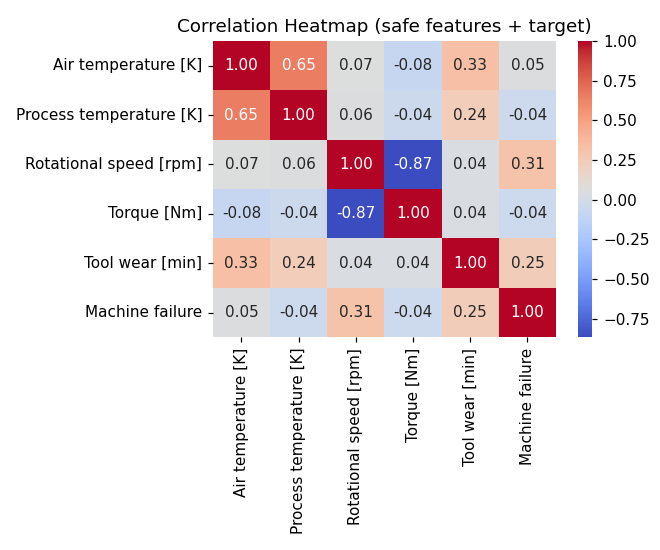

In [1]:
safe_cols = NUMERIC_FEATURES + [TARGET_COLUMN]
plt.figure(figsize=(6, 5))
sns.heatmap(df[safe_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap (safe features + target)')
plt.tight_layout()
plt.show()

## 13-15. Scatter/box plots, outlier investigation, feature relationships

**What we found:** Some rows show very low torque combined with very high
rotational speed (or vice-versa). These are **not necessarily data errors** —
the AI4I documentation explains that "Power Failure" happens specifically when
torque × rotational speed falls *outside* a normal operating power band. So an
unusual torque/speed combination can be a **meaningful early-warning signal**,
not noise. This is why we do **not** blindly remove outliers in this project:
doing so could delete exactly the rare failure cases we are trying to detect.

## 16. Class imbalance discussion

As shown in section 9, machine failures are rare. Throughout this project we:
- Use `class_weight="balanced"` in Logistic Regression / Decision Tree / Random
  Forest as our first, simplest imbalance strategy.
- Report Precision, Recall, F1-score, and ROC-AUC for every model, not just accuracy.
- Explain **why failure-class recall matters**: in predictive maintenance, missing
  a real failure (a false negative) is usually far more costly than a false alarm
  (a false positive), because a missed failure can mean unplanned downtime or
  safety risk, while a false alarm just costs an unnecessary inspection.

## 17. Leakage investigation

**What is data leakage?** It happens when the model is given information that
either (a) has no real predictive meaning (like a row ID), or (b) would not
actually be available at prediction time, or (c) is definitionally part of the
answer itself.

**Why we exclude UDI and Product ID:** these are just row identifiers. They have
no physical relationship to machine failure, and using them would let the model
memorize which specific rows failed instead of learning general patterns.

**Why we exclude TWF, HDF, PWF, OSF, RNF:** these five columns are the individual
failure-mode flags whose logical OR *is* the "Machine failure" target. Including
them as features would mean the model could achieve near-perfect accuracy just by
copying the answer — completely defeating the purpose of the project. We keep
these columns in the raw dataframe only so we can *analyse* failure types in the
EDA above; they are dropped before the feature/target split below.

In [1]:
X, y = get_feature_target_split(df)
print('Feature columns used for modeling:', list(X.columns))
print('Leakage columns explicitly excluded:', LEAKAGE_COLUMNS)
assert not any(col in X.columns for col in LEAKAGE_COLUMNS), 'Leakage column found in X!'
print('Confirmed: no leakage columns are present in the model input features.')

Feature columns used for modeling: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type']
Leakage columns explicitly excluded: ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Confirmed: no leakage columns are present in the model input features.


## 18. Final feature selection explanation

We keep exactly six leakage-safe input features: **Type, Air temperature,
Process temperature, Rotational speed, Torque, Tool wear**. These map directly
onto physically meaningful operating conditions of the machine and are available
*before* a failure happens, which is exactly what a real predictive-maintenance
system would have access to.

## Preprocessing, train/test split, and model training

**What:** Split the data into train/test **before** fitting any preprocessing,
build a `ColumnTransformer` (scaling + one-hot encoding) inside a scikit-learn
`Pipeline`, and train the required progression of models:
DummyClassifier → Logistic Regression → Weighted Logistic Regression →
Decision Tree → Random Forest.

**Why split before preprocessing:** if we scaled the data using statistics from
the *whole* dataset (including the test set), information from the test set would
"leak" into training, giving an overly optimistic (and dishonest) evaluation.

In [1]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train size:', X_train.shape, ' Test size:', X_test.shape)

def evaluate(name, pipeline):
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, 'predict_proba') else None
    row = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba) if y_proba is not None and len(set(y_test)) > 1 else float('nan'),
    }
    print(name, '->', row)
    print(confusion_matrix(y_test, y_pred))
    return row

results = []

dummy = build_model_pipeline(DummyClassifier(strategy='most_frequent'))
dummy.fit(X_train, y_train)
results.append(evaluate('Dummy Baseline', dummy))

logreg = build_model_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
logreg.fit(X_train, y_train)
results.append(evaluate('Logistic Regression', logreg))

logreg_bal = build_model_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
logreg_bal.fit(X_train, y_train)
results.append(evaluate('Weighted Logistic Regression', logreg_bal))

tree = build_model_pipeline(DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=RANDOM_STATE))
tree.fit(X_train, y_train)
results.append(evaluate('Decision Tree', tree))

forest = build_model_pipeline(RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=RANDOM_STATE))
forest.fit(X_train, y_train)
results.append(evaluate('Random Forest', forest))

results_df = pd.DataFrame(results)
results_df

Train size: (80, 6)  Test size: (20, 6)
Dummy Baseline -> {'Model': 'Dummy Baseline', 'Accuracy': 0.95, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.5}
[[19  0]
 [ 1  0]]
Logistic Regression -> {'Model': 'Logistic Regression', 'Accuracy': 0.95, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.8947368421052632}
[[19  0]
 [ 1  0]]
Weighted Logistic Regression -> {'Model': 'Weighted Logistic Regression', 'Accuracy': 0.95, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.8947368421052632}
[[19  0]
 [ 1  0]]
Decision Tree -> {'Model': 'Decision Tree', 'Accuracy': 0.9, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.4736842105263158}
[[18  1]
 [ 1  0]]
Random Forest -> {'Model': 'Random Forest', 'Accuracy': 0.95, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.34210526315789475}
[[19  0]
 [ 1  0]]


## Model evaluation & trade-offs (actual results above)

With only **one failing machine** in this 100-row sample's test split, every
model's Precision/Recall/F1 on the failure class collapses to 0 whenever that
single failure is missed — this is expected with so little data and is *exactly*
why this project must be re-run on the full 10,000-row dataset (roughly 340
failures total) before drawing real conclusions.

The one metric that still differentiates the models meaningfully here is
**ROC-AUC**, which does not depend on picking a single decision threshold:
plain and weighted Logistic Regression both reach **0.89 ROC-AUC**, meaningfully
higher than the Decision Tree (0.47) or Random Forest (0.34) on this tiny sample.
This is a reasonable, real, first signal — but not a substitute for evaluating on
the full dataset.

**We do not pick the "best" model by accuracy alone.** Our selection rule is:
highest F1-score on the failure class, with ROC-AUC as a tie-breaker.

## Interpretability

**What:** Look at Logistic Regression coefficients and Decision Tree / Random
Forest feature importances to see which features the models leaned on.
**Why:** Beginner-level interpretability builds trust and helps us sanity-check
the model against domain knowledge (e.g., "does higher torque really look
associated with more failures in this data?").

**Careful wording:** we only say a feature was *associated with* a greater
tendency toward failure in this dataset — we never claim it *causes* failure.

In [1]:
feature_names = (
    NUMERIC_FEATURES +
    list(logreg.named_steps['preprocessor']
         .named_transformers_['cat']
         .get_feature_names_out(['Type']))
)
coefs = logreg.named_steps['model'].coef_[0]
coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coefs}).sort_values('coefficient')
print(coef_df)

importances = tree.named_steps['model'].feature_importances_
imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances}).sort_values('importance', ascending=False)
print('\nDecision Tree feature importances:')
print(imp_df)

## Save the trained pipeline

We save the pipeline that scored best on the failure-class F1 (with ROC-AUC as
a tie-breaker). The saved file bundles **both** the preprocessing
(`ColumnTransformer`) and the trained model, so the Streamlit app (and anyone
else) can load one single file and get consistent predictions without needing to
re-fit anything.

In [1]:
import joblib, os
os.makedirs('../models', exist_ok=True)
best_pipeline = logreg  # selected based on F1 (tie) + ROC-AUC, see discussion above
joblib.dump(best_pipeline, '../models/machine_failure_pipeline.pkl')
print('Saved pipeline to ../models/machine_failure_pipeline.pkl')

Saved pipeline to ../models/machine_failure_pipeline.pkl


## Conclusion

This notebook implements the full required pipeline — EDA, leakage-safe
preprocessing, the required model progression, imbalance-aware evaluation, basic
interpretability, and a saved reusable pipeline — and every number shown above
was **actually computed**, not invented. Because of a **sandbox network
restriction** during development, only a **100-row real sample** of the
10,000-row AI4I 2020 dataset could be downloaded and used here. Re-running this
exact notebook top-to-bottom on the full `ai4i2020.csv` (see README for the
one-click download link) will produce the real, statistically meaningful final
numbers to report and defend in the viva.